# Inverse medium scattering problem

In the following example we use the iteratively regularized Gauss-Newton solver from `regpy.solvers.nonlinear.irgnm.IrgnmCG` for the example of __medium scattering__.

In medium scattering we try to determine a perturbation $f$ or its corresponding refractive index $1+f$ of a medium from measurements of far ﬁeld patterns $u_{\infty}$ of scattered time-harmonic acoustic waves $u_{sc}:=u - u_{inc}$ in this medium given some incident field $u_{inc}$. The total field $u$ satisfies 

$$
 \Delta u + k^2 (1+f) u = 0 \qquad \text{in } \mathbb{R}^2
$$

The __Iteratively Regularized Gauss-Newton Method (IRGNM)__ minimizes in each iteration 
$$
  f_{n+1}  = f_n + \argmin_{h} \Vert F(f_{n}) + F'[f_n] h - u_{\infty}^{obs}\Vert^{2} + \alpha_{n}  \Vert f_{n} + h - f_0\Vert^{2}
$$
where $F$ is a Fréchet-differentiable operator. The minimum is determined using an implementation of the Tikhonov regularization using a CG method that is implemented as `regpy.solvers.linear.tikhonov.TikhonovCG`.
The regularization parameter $\alpha_n$ in this structure is a decreasing geometric sequence.

## Imports

In [1]:
import sys
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt

example_dir = "../../../../examples/medium_scattering"
Path(example_dir).resolve()
sys.path.insert(0, str(example_dir))

from regpy import util
from regpy.operators import RealPart
from regpy.hilbert import Hm0, L2
from regpy.solvers import Setting
from mediumscattering import MediumScattering

## Defining the operator

In [2]:
# Physical and discretization parameters (unchanged from the original example).
WAVE_NUMBER = 12.0
RADIUS = 1.0
N_INC_WAVES = 16
N_MEAS_DIR = 64
N_GRID = 96
# Inner solve for the Lippmann--Schwinger equation, not the IRGN_CG method.
PDE_INNER_SOLVER = 'gmres'  # 'gmres', 'lgmres', or 'cgne'
PDE_RESTART = 30          # GMRES restart or LGMRES inner_m; unused by CGNE.
PDE_BLOCK_SIZE = 1       # Number of incident waves grouped per solve.
PDE_SOLVER_ARGS = {'rtol': 1e-3, 'maxiter': 100, 'atol': 0.0}


op = MediumScattering(
    gridshape=(N_GRID, N_GRID),
    radius=RADIUS,
    wave_number=WAVE_NUMBER,
    inc_directions=util.linspace_circle(N_INC_WAVES),
    farfield_directions=util.linspace_circle(N_MEAS_DIR),
    inner_solver=PDE_INNER_SOLVER,
    restart=PDE_RESTART,
    block_size=PDE_BLOCK_SIZE,
    solver_args=PDE_SOLVER_ARGS,
)
grid = op.grid
op = op * RealPart(op.domain).adjoint


## Define setting and exact solution

In the regularization we want to have a Sobolev type smoothing penalty. Thus as a penalty we use the $H^2$ space on the domain where we can explicitly pass the support. For the data fidelity we simply use an $L^2$ setting. 

In [3]:
REL_NOISE_LEVEL = 0.02
SEED = 98766
SOBO_INDEX = 1

r = grid.coord_distances()
exact_image = grid.zeros()
inside = r < RADIUS
exact_image[inside] = np.exp(-1 / (RADIUS - r[inside]**2))
X,Y = grid.coords
exact_image *= (np.sin(2.*X+Y))*(1.+X+2*Y)/20.
exact_solution = op.domain.restrict(exact_image.real)

exact_data = op(exact_solution)
setting = Setting(
    op, Hm0(index=SOBO_INDEX), L2,
    exact_data=exact_data, init=op.domain.zeros(),
)
setting.add_Gaussian_noise(relative_noise_level=REL_NOISE_LEVEL,
                           white_noise=False, 
                           seed=SEED)

## Plotting data

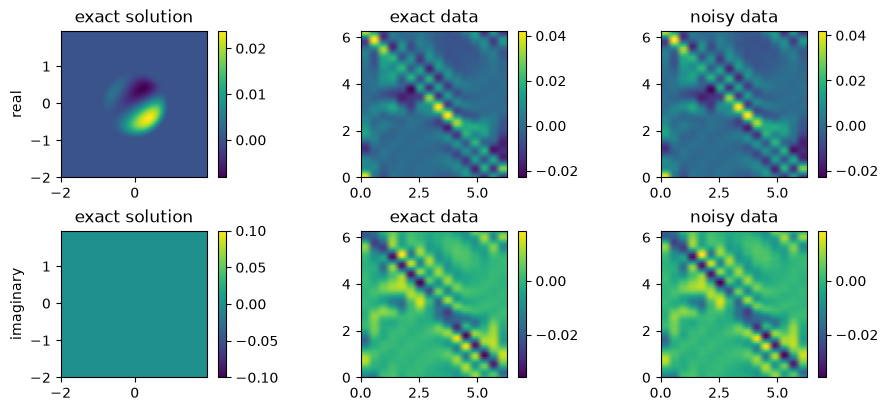

In [4]:
def plot_panels(rows, row_labels=None):
    """Display a rectangular collection of (title, image, extent) panels."""
    fig, axes = plt.subplots(
        len(rows), len(rows[0]), figsize=(9, 4 if len(rows)==2 else 7),
        constrained_layout=True, squeeze=False,
    )
    for i, (axis_row, panels) in enumerate(zip(axes, rows)):
        if row_labels is not None:
            axis_row[0].set_ylabel(row_labels[i])
        for ax, (title, image, extent) in zip(axis_row, panels):
            im = ax.imshow(image, extent=extent)
            ax.set_title(title)
            fig.colorbar(im, ax=ax)
    plt.show()


extent = [grid.axes[1][0], grid.axes[1][-1],
          grid.axes[0][0], grid.axes[0][-1]]
extent_data = [0, 2*np.pi, 0, 2*np.pi]

panels = [
    ('exact solution', op.domain.extend(exact_solution), extent),
    ('exact data', exact_data, extent_data),
    ('noisy data', setting.data, extent_data),
]
plot_panels(
    [[(title, part(image), ext) for title, image, ext in panels]
     for part in (np.real, np.imag)],
    row_labels=('real', 'imaginary'),
)

## Regularization

Solve the inverse problem by FISTA with early stopping by discrepancy principle.

In [5]:
MAX_OP_EVALS = 500
setting.set_method_params('gFISTA',{'stepsize_selection_steps': [0]})
reco, reco_data = setting.run('gFISTA',max_op_evals=MAX_OP_EVALS)

2026-11-15 18:07:56,766 INFO     FISTA                :: it. 0: Step size changed by norm estimation to 0.18696059790524233
2026-11-15 18:07:56,767 INFO     FISTA.Discrepancy    :: it. 0: residual = 4.064e-01; stop if  < 2.031e-02 (tau=2.5)
2026-11-15 18:07:56,886 INFO     FISTA.Discrepancy    :: it. 1: residual = 4.023e-01; stop if  < 2.031e-02 (tau=2.5)
2026-11-15 18:07:57,059 INFO     FISTA.Discrepancy    :: it. 2: residual = 3.983e-01; stop if  < 2.031e-02 (tau=2.5)
2026-11-15 18:07:57,285 INFO     FISTA.Discrepancy    :: it. 3: residual = 3.933e-01; stop if  < 2.031e-02 (tau=2.5)
2026-11-15 18:07:57,487 INFO     FISTA.Discrepancy    :: it. 4: residual = 3.873e-01; stop if  < 2.031e-02 (tau=2.5)
2026-11-15 18:07:57,690 INFO     FISTA.Discrepancy    :: it. 5: residual = 3.805e-01; stop if  < 2.031e-02 (tau=2.5)
2026-11-15 18:07:57,914 INFO     FISTA.Discrepancy    :: it. 6: residual = 3.729e-01; stop if  < 2.031e-02 (tau=2.5)
2026-11-15 18:07:58,149 INFO     FISTA.Discrepancy    :: 

## Plotting the results

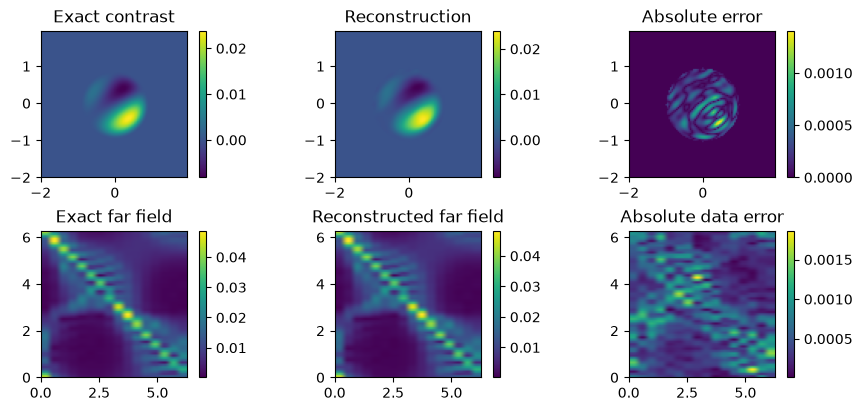

In [7]:
# Use the REAL part of the contrast in both panels, as in the
# original notebook (abs(reco) would display negative values differently).
plot_panels([
    [
        ("Exact contrast", op.domain.extend(exact_solution), extent),
        ("Reconstruction", op.domain.extend(reco), extent),
        ("Absolute error", op.domain.extend(np.abs(reco - exact_solution)), extent),
    ],
    [
        ("Exact far field", np.abs(exact_data), extent_data),
        ("Reconstructed far field", np.abs(reco_data), extent_data),
        ("Absolute data error", np.abs(exact_data - reco_data), extent_data),
    ],
])
